<a href="https://colab.research.google.com/github/Dimas-091206/Proyek-Akhir-Kelompok-9-Online-Retail-II/blob/main/Eksploratory_Data_Online_Retail_II.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tahap 1 Proyek Akhir: Eksplorasi Data Online Retail II
**Mata Kuliah:** Pembelajaran Mesin (INF62325) | **Paket:** 5B-9 Online Retail II | **Berkas:** `online_retail_II.xlsx`
**Kelompok / anggota:** _(isi)_  |  **Metode kelompok:** _(Regresi Linear / Klasifikasi / Klastering, hapus cabang yang tidak dipakai di Langkah 4)_

Notebook ini mengikuti **Delapan Langkah Eksplorasi Data** pada Panduan Tahap 1, sel demi sel:

| Langkah | Isi |
|---|---|
| 0 | Baca sumber dataset |
| 1 | Muat data dengan benar |
| 2 | Potret struktur dan unit analisis |
| 3 | Pemeriksaan kebersihan (enam pemeriksaan) |
| 3.5 | Pembersihan berdasarkan keputusan, lalu agregasi ke tingkat pelanggan |
| 4 | Variabel target (cabang A regresi, B klasifikasi, C klastering) |
| 5 | Hubungan antar variabel dan kebocoran data |
| 6 | Rekap visualisasi |
| 7 | Tabel keputusan, kamus data, simpan data bersih |

> **Catatan.** Semua angka dihasilkan oleh kode di notebook ini. Teks **Tafsir** ditulis berdasarkan hasil eksekusi terakhir; pahami lalu tulis ulang dengan kalimat Anda sendiri.

In [4]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 100

## Langkah 0 - Baca halaman sumber sebelum menulis kode

Sumber: UCI Machine Learning Repository, *Online Retail II* (https://archive.ics.uci.edu/dataset/502/online+retail+ii).

- Satu baris data mewakili apa?
Satu baris item pada satu faktur (satu produk pada satu faktur). Dan satu transaksi terdiri dari banyak baris.

- Arti dan satuan, kolom
'Invoice' berarti nomor faktur (dengan awalan 'C' merupakan nota kredit/pembatalan), 'StockCode' berarti kode produk, 'Description' berarti nama produk, 'Quantity' berarti jumlah unit perbaris, 'InvoiceDate' berarti waktu faktur, 'Price' berarti harga satuan dalam poundsterling (GBP), 'Customer ID' berarti nomor pelanggan.

- Kolom yang berupa kode yaitu 'Invoice', 'StokCode', dan 'Customer ID'. Kolom identitas yang bukan merupakan besaran numerik. Awalan huruf pada 'Invoice' dan 'StockCode' membawa arti khusus

- Cara dan waktu pengumpulan data yaitu Transaksi nyata sebuah toko daring berbasis di Inggris (tanpa toko fisik), 1 Des 2009 sampai 9 Des 2011. Bukan data sintetis. Banyak pelanggan adalah pedagang grosir.

- Apa yang tidak ada? Kategori produk, harga pokok/margin, atribut demografis pelanggan, status pesanan, dan 'Customer ID' untuk sebagian transaksi (pembeli tanpa akun). Karena itu analisis "per pelanggan" hanya bisa mencakup transaksi yang punya 'Customer ID'


## Langkah 1 - Muat data dengan benar

Berkas `.xlsx` ini punya **dua lembar** (2009-2010 dan 2010-2011), jadi dibaca dengan `sheet_name=None` lalu digabung. Pemuatan lambat (sekitar satu menit), sehingga hasil gabungan disimpan ke CSV sebagai *cache*.

In [5]:
import os
import pandas as pd

FOLDER = '/content'                                      # folder kerja default Google Colab
BERKAS_XLSX = f'{FOLDER}/online_retail_II.xlsx'          # berkas yang diunggah ke Colab
BERKAS_GABUNGAN = f'{FOLDER}/online_retail_II_gabungan.csv'  # cache hasil gabungan dua lembar

if os.path.exists(BERKAS_GABUNGAN):
    df = pd.read_csv(BERKAS_GABUNGAN, dtype={'Invoice': str, 'StockCode': str, 'Description': str},
                     parse_dates=['InvoiceDate'])
    print('dibaca dari cache CSV:', BERKAS_GABUNGAN)
elif os.path.exists(BERKAS_XLSX):
    lembar = pd.read_excel(BERKAS_XLSX, sheet_name=None)
    for nama, d_ in lembar.items():
        print(f'lembar {nama!r}: {d_.shape}')
    df = pd.concat(lembar.values(), ignore_index=True)
    df.to_csv(BERKAS_GABUNGAN, index=False)
    print('gabungan disimpan ke', BERKAS_GABUNGAN)
else:
    raise FileNotFoundError(f'{BERKAS_XLSX} tidak ditemukan. Unggah online_retail_II.xlsx ke panel Files di Colab '
                            f'(ikon folder di kiri), lalu jalankan ulang sel ini.')

# Invoice dan StockCode bercampur angka dan huruf, jadi perlakukan sebagai teks
df['Invoice'] = df['Invoice'].astype(str)
df['StockCode'] = df['StockCode'].astype(str)
# Description memuat 4 nilai bertipe angka pada berkas Excel; samakan menjadi teks (nilai kosong tetap kosong)
df['Description'] = df['Description'].map(lambda x: x if pd.isna(x) else str(x))

print('\nbentuk data      :', df.shape)
print('sesuai tabel paket (1.067.371 x 8):', df.shape == (1067371, 8))
print('jumlah kolom > 1 :', df.shape[1] > 1)
print('periode          :', df['InvoiceDate'].min(), 's.d.', df['InvoiceDate'].max())
print('berkas sumber    : online_retail_II.xlsx (lembar: Year 2009-2010 dan Year 2010-2011)')

lembar 'Year 2009-2010': (525461, 8)
lembar 'Year 2010-2011': (541910, 8)
gabungan disimpan ke /content/online_retail_II_gabungan.csv

bentuk data      : (1067371, 8)
sesuai tabel paket (1.067.371 x 8): True
jumlah kolom > 1 : True
periode          : 2009-12-01 07:45:00 s.d. 2011-12-09 12:50:00
berkas sumber    : online_retail_II.xlsx (lembar: Year 2009-2010 dan Year 2010-2011)


**Daftar periksa Langkah 1**
- [x] Bentuk data sesuai tabel paket (hasil di atas).
- [x] Jumlah kolom lebih dari satu (format Excel, tidak ada masalah pemisah/encoding).
- [x] Nama berkas dicatat untuk laporan: `online_retail_II.xlsx`, dua lembar digabung.
- [x] Penanda data hilang teks khas: tidak ada `?`/`unknown` pada pembacaan; data hilang tersamar dicari manual di Langkah 3b.

## Langkah 2 - Potret struktur dan unit analisis

In [6]:
display(df.head(10))
df.info()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,"13,085.00",United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,"13,085.00",United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,"13,085.00",United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,"13,085.00",United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


In [7]:
display(df.describe())
display(df.select_dtypes(exclude=['number', 'datetime']).describe())

,Quantity,InvoiceDate,Price,Customer ID
count,"1,067,371.00",1067371,"1,067,371.00","824,364.00"
mean,9.94,2011-01-02 21:13:55.394028544,4.65,"15,324.64"
min,"-80,995.00",2009-12-01 07:45:00,"-53,594.36","12,346.00"
25%,1.00,2010-07-09 09:46:00,1.25,"13,975.00"
50%,3.00,2010-12-07 15:28:00,2.10,"15,255.00"
75%,10.00,2011-07-22 10:23:00,4.15,"16,797.00"
max,"80,995.00",2011-12-09 12:50:00,"38,970.00","18,287.00"
std,172.71,NaN,123.55,"1,697.46"


,Invoice,StockCode,Description,Country
count,1067371,1067371,1062989,1067371
unique,53628,5305,5698,43
top,537434,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1350,5829,5918,981330


**Ketidaksesuaian tipe dan arti** (ketiganya adalah temuan yang harus dicatat):

| Kolom | Tipe terbaca | Arti sebenarnya | Tindakan |
|---|---|---|---|
| `Customer ID` | float64 (karena ada nilai kosong) | identifier, bukan besaran | diubah ke teks setelah baris kosong disingkirkan |
| `Invoice` | teks bercampur angka dan huruf | identifier; awalan C = pembatalan | dipisah menjadi penanda `batal` |
| `StockCode` | teks | identifier produk; sebagian bukan produk (ongkir, biaya) | kode non-produk ditandai dan dibuang |
| `Description` | teks, ada nilai kosong dan empat nilai angka | nama produk | dinormalisasi (Langkah 3f) |

In [8]:
n_baris = len(df)
n_faktur = df['Invoice'].nunique()
n_pelanggan_asli = df['Customer ID'].nunique()
print(f'baris (item faktur)          : {n_baris:,}')
print(f'faktur unik                  : {n_faktur:,}  (rata-rata {n_baris/n_faktur:.1f} baris per faktur)')
print(f'pelanggan unik (Customer ID) : {n_pelanggan_asli:,}')
print(f'rasio baris : pelanggan      : {n_baris/n_pelanggan_asli:,.0f} : 1')

baris (item faktur)          : 1,067,371
faktur unik                  : 53,628  (rata-rata 19.9 baris per faktur)
pelanggan unik (Customer ID) : 5,942
rasio baris : pelanggan      : 180 : 1


### Unit analisis

> **Satu baris data mentah = satu item pada satu faktur. Unit analisis untuk pemodelan = satu pelanggan** (`Customer ID`), diperoleh dengan agregasi `groupby` pada Langkah 3.5, sebelum pemodelan. Jumlah pelanggan hasil agregasi jauh lebih kecil daripada jumlah baris (lihat angka di atas dan di Langkah 3.5).

## Langkah 3 - Periksa kebersihan data (enam pemeriksaan)

### 3a. Nilai hilang

,jumlah,persen
Customer ID,243007,22.77
Description,4382,0.41



Baris Description kosong     : 4382
  harga semuanya nol?        : True
  punya Customer ID?         : 0 baris

Customer ID kosong per negara (5 terbanyak, persen dari baris kosong):
Country
United Kingdom   98.80
EIRE              0.70
Hong Kong         0.10
Unspecified       0.10
France            0.10
Name: proportion, dtype: float64


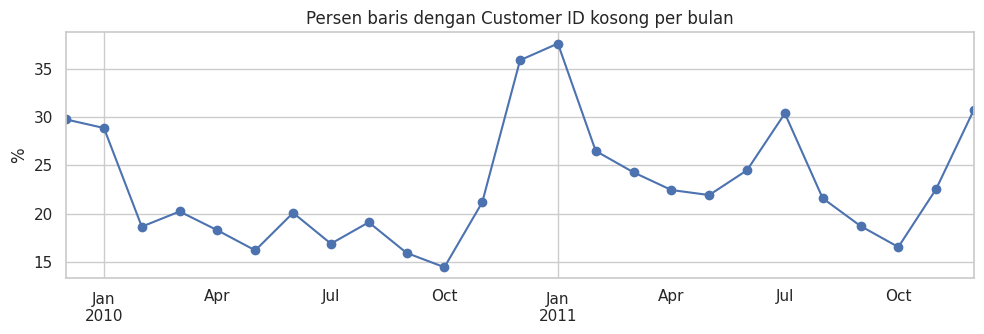

In [9]:
hilang = pd.DataFrame({'jumlah': df.isna().sum(),
                       'persen': (df.isna().mean() * 100).round(2)}).sort_values('persen', ascending=False)
display(hilang[hilang['jumlah'] > 0])

# Apakah kosongnya acak? (1) kolom Description kosong: harganya berapa, (2) Customer ID kosong: per bulan dan per negara
kosong_desc = df[df['Description'].isna()]
print('\nBaris Description kosong     :', len(kosong_desc))
print('  harga semuanya nol?        :', (kosong_desc['Price'] == 0).all())
print('  punya Customer ID?         :', kosong_desc['Customer ID'].notna().sum(), 'baris')

kosong_pel = df['Customer ID'].isna()
print('\nCustomer ID kosong per negara (5 terbanyak, persen dari baris kosong):')
print((df.loc[kosong_pel, 'Country'].value_counts(normalize=True).head(5) * 100).round(1))

per_bulan = kosong_pel.groupby(df['InvoiceDate'].dt.to_period('M')).mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.5))
per_bulan.plot(ax=ax, marker='o')
ax.set_title('Persen baris dengan Customer ID kosong per bulan'); ax.set_ylabel('%'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

**Tafsir.** `Customer ID` kosong pada 22,77% baris (243.007) dan `Description` pada 0,41% (4.382). Semua baris `Description` kosong berharga nol dan tanpa `Customer ID`, jadi tampaknya penyesuaian stok, bukan data hilang acak. Kosongnya `Customer ID` juga tidak merata: berkisar sekitar 14% sampai 38% per bulan dan memuncak sekitar Desember 2010-Januari 2011, sehingga pembeli tanpa akun bukan sampel acak dan analisis per pelanggan hanya mewakili pembeli ber-akun.

### 3b. Data hilang yang tersamar

In [10]:
batal = df['Invoice'].str.startswith('C')
print('Price == 0                  :', (df['Price'] == 0).sum())
print('Price  < 0                  :', (df['Price'] < 0).sum())
print('Quantity <= 0               :', (df['Quantity'] <= 0).sum())
print('\nTabel silang: tanda Quantity vs awalan C pada Invoice')
print(pd.crosstab(df['Quantity'] > 0, batal, rownames=['Quantity > 0'], colnames=['Invoice berawalan C']))

print('\nAwalan non-angka pada Invoice:')
print(df.loc[~df['Invoice'].str.fullmatch(r'\d+'), 'Invoice'].str[0].value_counts())
print(df[df['Invoice'].str.startswith('A')])

print('\nDescription yang isinya hanya angka (tidak masuk akal sebagai nama produk):')
print(df.loc[df['Description'].fillna('').str.fullmatch(r'\d+'), ['Invoice', 'StockCode', 'Description', 'Quantity', 'Price']])

print('\nNegara bernilai tidak jelas:')
print(df['Country'].isin(['Unspecified', 'European Community']).groupby(df['Country']).sum().loc[['Unspecified', 'European Community']])

Price == 0                  : 6202
Price  < 0                  : 5
Quantity <= 0               : 22950

Tabel silang: tanda Quantity vs awalan C pada Invoice
Invoice berawalan C    False  True 
Quantity > 0                       
False                   3457  19493
True                 1044420      1

Awalan non-angka pada Invoice:
Invoice
C    19494
A        6
Name: count, dtype: int64
        Invoice StockCode      Description  Quantity         InvoiceDate      Price  Customer ID         Country
179403  A506401         B  Adjust bad debt         1 2010-04-29 13:36:00 -53,594.36          NaN  United Kingdom
276274  A516228         B  Adjust bad debt         1 2010-07-19 11:24:00 -44,031.79          NaN  United Kingdom
403472  A528059         B  Adjust bad debt         1 2010-10-20 12:04:00 -38,925.87          NaN  United Kingdom
825443  A563185         B  Adjust bad debt         1 2011-08-12 14:50:00  11,062.06          NaN  United Kingdom
825444  A563186         B  Adjust bad debt   

In [11]:
# Kode barang yang bukan produk: pola produk = 5 angka + 0-2 huruf (mis. 85048, 79323P)
bukan_produk = ~df['StockCode'].str.fullmatch(r'\d{5}[A-Za-z]{0,2}')
tabel_kode = (df[bukan_produk].groupby('StockCode')
              .agg(baris=('Quantity', 'size'),
                   contoh_deskripsi=('Description', 'first'),
                   baris_ber_pelanggan=('Customer ID', lambda s: s.notna().sum()))
              .sort_values('baris', ascending=False))
print('baris dengan StockCode tidak berpola produk:', bukan_produk.sum(), 'dari', len(df))
display(tabel_kode.head(25))

baris dengan StockCode tidak berpola produk: 6094 dari 1067371


,baris,contoh_deskripsi,baris_ber_pelanggan
StockCode,,,
POST,2122,POSTAGE,2019
DOT,1446,DOTCOM POSTAGE,16
M,1421,Manual,1115
C2,282,CARRIAGE,259
D,177,Discount,174
S,104,SAMPLES,0
BANK CHARGES,102,Bank Charges,38
ADJUST,67,Adjustment by john on 26/01/2010 16,61
AMAZONFEE,43,AMAZON FEE,0


**Tafsir.** `isna()` tidak menemukan semua ini: 6.202 baris `Price` = 0 dan 5 baris `Price` negatif (semuanya faktur berawalan A, 'Adjust bad debt'), 3.457 baris `Quantity` negatif tanpa awalan C (tidak ada yang tersisa setelah pembersihan di Langkah 3.5), 6.094 baris berkode non-produk (POST, DOT, M, C2, D, BANK CHARGES, dst.), 4 `Description` berisi angka, dan negara bernilai 'Unspecified' (756 baris) serta 'European Community' (61 baris). Hasilnya tidak nol, jadi pembersihan memang perlu.

### 3c. Duplikat

In [12]:
dup_penuh = df.duplicated(keep='first')
print('baris identik seluruhnya (salinan ke-2 dst):', dup_penuh.sum(), f'({dup_penuh.mean()*100:.2f}%)')
print('  faktur yang terdampak                    :', df[df.duplicated(keep=False)]['Invoice'].nunique())
print('  di antaranya ber-Customer ID             :', df[dup_penuh]['Customer ID'].notna().sum())
print('Invoice berulang (wajar, satu faktur banyak baris):', df['Invoice'].duplicated().sum())
print('pasangan (Invoice, StockCode) berulang     :', df.duplicated(['Invoice', 'StockCode']).sum(), '-> hanya sebagian yang identik penuh')

display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(6))

baris identik seluruhnya (salinan ke-2 dst): 34335 (3.22%)
  faktur yang terdampak                    : 5391
  di antaranya ber-Customer ID             : 26479
Invoice berulang (wajar, satu faktur banyak baris): 1013743
pasangan (Invoice, StockCode) berulang     : 45947 -> hanya sebagian yang identik penuh


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,"16,329.00",United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,"16,329.00",United Kingdom
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,"16,329.00",United Kingdom


Pada data transaksi, baris yang sama belum tentu duplikat. Namun di sini baris identik muncul pada **faktur yang sama dan menit yang sama** dengan produk, jumlah, dan harga yang sama, pola khas pencatatan ganda. **Keputusan sementara:** dibuang, dengan **uji sensitivitas** di Langkah 7 (seberapa besar pengaruhnya pada total belanja pelanggan).

### 3d. Kolom konstan dan identifier

In [13]:
n = df.nunique()
print('kolom konstan        :', list(n[n <= 1].index))
print('hampir unik per baris:', list(n[n > 0.9 * len(df)].index))
display(n.to_frame('nilai_unik').assign(persen_dari_baris=(n / len(df) * 100).round(2)))

kolom konstan        : []
hampir unik per baris: []


,nilai_unik,persen_dari_baris
Invoice,53628,5.02
StockCode,5305,0.50
Description,5698,0.53
Quantity,1057,0.10
InvoiceDate,47635,4.46
Price,2807,0.26
Customer ID,5942,0.56
Country,43,0.00


Tidak ada kolom konstan dan tidak ada kolom yang unik pada >90% baris. Namun `Invoice`, `StockCode`, dan `Customer ID` tetap **identifier menurut artinya** (kode, bukan besaran): berguna untuk menelusuri dan mengagregasi data, tetapi **tidak boleh dijadikan fitur**.

### 3e. Nilai mustahil dan pencilan (diperiksa per kolom)

Kuantil kolom numerik:


,0.00,0.01,0.25,0.50,0.75,0.99,1.00
Quantity,-112.63,-3.00,1.00,3.00,10.00,100.00,500.00
Price,0.00,0.21,1.25,2.10,4.15,18.00,217.02



8 baris dengan nilai (Quantity x Price) terbesar:


,Invoice,StockCode,Description,Quantity,Price,Customer ID,nilai
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"16,446.00","168,469.60"
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"12,346.00","77,183.60"
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.50,"15,098.00","38,970.00"
241827,512771,M,Manual,1,"25,111.09",NaN,"25,111.09"
432176,530715,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,9360,1.69,"15,838.00","15,818.40"
517955,537632,AMAZONFEE,AMAZON FEE,1,"13,541.33",NaN,"13,541.33"
540478,537632,AMAZONFEE,AMAZON FEE,1,"13,541.33",NaN,"13,541.33"
825443,A563185,B,Adjust bad debt,1,"11,062.06",NaN,"11,062.06"


8 baris dengan nilai terkecil:


,Invoice,StockCode,Description,Quantity,Price,Customer ID,nilai
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,"16,446.00","-168,469.60"
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,"12,346.00","-77,183.60"
179403,A506401,B,Adjust bad debt,1,"-53,594.36",NaN,"-53,594.36"
276274,A516228,B,Adjust bad debt,1,"-44,031.79",NaN,"-44,031.79"
748142,C556445,M,Manual,-1,"38,970.00","15,098.00","-38,970.00"
403472,A528059,B,Adjust bad debt,1,"-38,925.87",NaN,"-38,925.87"
241824,C512770,M,Manual,-1,"25,111.09","17,399.00","-25,111.09"
320581,C520667,BANK CHARGES,Bank Charges,-1,"18,910.69",NaN,"-18,910.69"


Quantity : di luar pagar 1,5xIQR = 116,489 baris (10.9%)  <- sekadar informasi, BUKAN dasar pembuangan
Price    : di luar pagar 1,5xIQR = 68,105 baris (6.4%)  <- sekadar informasi, BUKAN dasar pembuangan


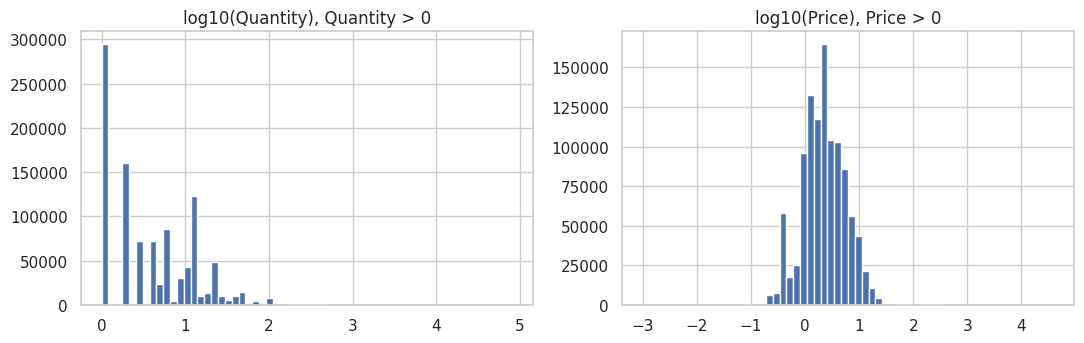

In [14]:
print('Kuantil kolom numerik:')
display(df[['Quantity', 'Price']].quantile([0.001, 0.01, 0.25, 0.5, 0.75, 0.99, 0.999]).T)

nilai = df['Quantity'] * df['Price']
kolom_tampil = ['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID']
print('\n8 baris dengan nilai (Quantity x Price) terbesar:')
display(df.assign(nilai=nilai).nlargest(8, 'nilai')[kolom_tampil + ['nilai']])
print('8 baris dengan nilai terkecil:')
display(df.assign(nilai=nilai).nsmallest(8, 'nilai')[kolom_tampil + ['nilai']])

# IQR hanya DIHITUNG untuk dilaporkan, tidak dipakai membuang apa pun
for k in ['Quantity', 'Price']:
    q1, q3 = df[k].quantile([0.25, 0.75]); iqr = q3 - q1
    luar = ((df[k] < q1 - 1.5 * iqr) | (df[k] > q3 + 1.5 * iqr)).sum()
    print(f'{k:9s}: di luar pagar 1,5xIQR = {luar:,} baris ({luar/len(df)*100:.1f}%)  <- sekadar informasi, BUKAN dasar pembuangan')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].hist(np.log10(df.loc[df['Quantity'] > 0, 'Quantity']), bins=60); ax[0].set_title('log10(Quantity), Quantity > 0')
ax[1].hist(np.log10(df.loc[df['Price'] > 0, 'Price']), bins=60); ax[1].set_title('log10(Price), Price > 0')
plt.tight_layout(); plt.show()

**Tafsir.** `Quantity` dan `Price` menyebar sangat lebar (terlihat dari skala log). Nilai mustahil dan pencilan nyata harus dibedakan: `Price` negatif atau nol mustahil, sedangkan 80.995 unit pada faktur 581483 adalah transaksi nyata yang dibatalkan dengan jumlah sama pada faktur C581484 (pola serupa pada 74.215 unit milik pelanggan 12346). Pagar 1,5xIQR menandai 10,9% baris `Quantity` dan 6,4% `Price`; membuangnya otomatis akan memangkas data besar-besaran, sehingga pencilan tidak dibuang.

### 3f. Konsistensi label kategori

In [15]:
d_ = df.dropna(subset=['Description'])
print('Description dengan spasi di awal/akhir :', (d_['Description'] != d_['Description'].str.strip()).sum())
print('Description mengandung huruf kecil     :', d_['Description'].str.contains('[a-z]', na=False).sum(), '(umumnya baris non-produk: Manual, Discount, dst.)')

norm = d_['Description'].str.strip().str.upper().str.replace(r'\s+', ' ', regex=True)
mentah = d_.groupby('StockCode')['Description'].nunique()
rapi = norm.groupby(d_['StockCode']).nunique()
print('\nStockCode dengan >1 Description (mentah)        :', (mentah > 1).sum(), 'dari', len(mentah))
print('StockCode dengan >1 Description (setelah rapi)  :', (rapi > 1).sum())

contoh = rapi[rapi > 1].index[:4]
display(d_[d_['StockCode'].isin(contoh)].assign(norm=norm).groupby(['StockCode', 'norm']).size().rename('baris').reset_index())

print('\nNegara (43 nilai) :', sorted(df['Country'].unique()))
print('Country dengan spasi berlebih:', (df['Country'] != df['Country'].str.strip()).sum())

Description dengan spasi di awal/akhir : 213035
Description mengandung huruf kecil     : 5967 (umumnya baris non-produk: Manual, Discount, dst.)

StockCode dengan >1 Description (mentah)        : 1232 dari 4950
StockCode dengan >1 Description (setelah rapi)  : 1210


,StockCode,norm,baris
0,10080,CHECK,1
1,10080,GROOVY CACTUS INFLATABLE,28
2,10120,DOGGY RUBBER,78
3,10120,ZEBRA INVCING ERROR,1
4,10133,COLOURING PENCILS BROWN TUBE,301
5,10133,DAMAGED,1
6,15056N,EDWARDIAN PARASOL NATURAL,1077
7,15056N,WEDDING CO RETURNS?,1



Negara (43 nilai) : ['Australia', 'Austria', 'Bahrain', 'Belgium', 'Bermuda', 'Brazil', 'Canada', 'Channel Islands', 'Cyprus', 'Czech Republic', 'Denmark', 'EIRE', 'European Community', 'Finland', 'France', 'Germany', 'Greece', 'Hong Kong', 'Iceland', 'Israel', 'Italy', 'Japan', 'Korea', 'Lebanon', 'Lithuania', 'Malta', 'Netherlands', 'Nigeria', 'Norway', 'Poland', 'Portugal', 'RSA', 'Saudi Arabia', 'Singapore', 'Spain', 'Sweden', 'Switzerland', 'Thailand', 'USA', 'United Arab Emirates', 'United Kingdom', 'Unspecified', 'West Indies']
Country dengan spasi berlebih: 0


**Tafsir.** 213.035 `Description` memiliki spasi di awal atau akhir. Sebanyak 1.232 dari 4.950 `StockCode` punya lebih dari satu `Description`; setelah dirapikan masih 1.210 karena sisanya bukan beda ejaan, melainkan catatan manual gudang ('DAMAGED', 'CHECK', 'WEDDING CO RETURNS?') yang menimpa nama produk. Karena itu `Description` tidak dijadikan fitur, dan `StockCode` menjadi penentu produk.

## Langkah 3.5 - Pembersihan berdasarkan keputusan, lalu agregasi ke tingkat pelanggan

Setiap keputusan dicatat di `log` beserta alasannya dan **jumlah baris terpengaruh** (dihitung berurutan). Fungsi dibuat supaya bisa dijalankan dengan variasi keputusan untuk **uji sensitivitas** di Langkah 7.

In [16]:
POLA_NON_PRODUK = r'(?i)^(POST|DOT|M|C2|C3|D|S|B|BANK CHARGES|ADJUST2?|AMAZONFEE|CRUK|TEST\d+|PADS|gift_.*)$'

def bersihkan(df_in, dedupe=True, buang_nonproduk=True, catat=False):
    """Terapkan keputusan pembersihan secara berurutan. Mengembalikan (data_bersih, log)."""
    log = []
    def tulis(kolom, temuan, keputusan, alasan, sebelum, sesudah):
        if catat:
            log.append({'Kolom / baris': kolom, 'Temuan': temuan, 'Keputusan': keputusan,
                        'Alasan': alasan, 'Baris terpengaruh': sebelum - sesudah})
    d = df_in.copy()

    n = len(d)
    if dedupe:
        d = d.drop_duplicates()
        tulis('Baris identik penuh', 'Salinan ganda pada faktur dan menit yang sama', 'Dibuang (sisakan satu)',
              'Pola pencatatan ganda; dampaknya diuji pada uji sensitivitas Langkah 7', n, len(d))

    n = len(d)
    d = d[d['Customer ID'].notna()].copy()
    tulis('Customer ID kosong', 'Pembeli tanpa akun; tidak dapat dihubungkan ke pelanggan', 'Baris dibuang',
          'Unit analisis adalah pelanggan; baris tanpa ID tidak bisa diagregasi', n, len(d))

    n = len(d)
    if buang_nonproduk:
        d = d[~d['StockCode'].str.fullmatch(POLA_NON_PRODUK)].copy()
        tulis('StockCode non-produk', 'POST, DOT, M, C2, D, BANK CHARGES, ADJUST, CRUK, TEST, dll.', 'Baris dibuang',
              'Ongkir, biaya, dan penyesuaian bukan belanja produk; menggembungkan Monetary', n, len(d))

    n = len(d)
    d = d[d['Price'] > 0].copy()
    tulis('Price <= 0', 'Harga nol/negatif (penyesuaian dan koreksi stok)', 'Baris dibuang',
          'Harga satuan tidak mungkin nol/negatif pada penjualan nyata', n, len(d))

    n = len(d)
    d['Description'] = (d['Description'].str.strip().str.upper().str.replace(r'\s+', ' ', regex=True))
    tulis('Description', 'Spasi berlebih dan huruf besar/kecil tidak seragam', 'Diseragamkan (strip, UPPER)',
          'Satu produk tidak boleh terhitung sebagai beberapa label', n, len(d))

    d['Customer ID'] = d['Customer ID'].astype(int).astype(str)
    d['batal'] = d['Invoice'].str.startswith('C')
    d['nilai'] = d['Quantity'] * d['Price']
    tulis('Invoice berawalan C', 'Nota kredit/pembatalan (Quantity negatif)', 'Dipertahankan, ditandai kolom batal',
          'Dipakai sebagai fitur pembatalan; Monetary dihitung dua versi (kotor dan bersih)', len(d), len(d))
    return d, log

d, log = bersihkan(df, catat=True)
print('ukuran awal  :', df.shape)
print('ukuran bersih:', d.shape, f'({len(d)/len(df)*100:.1f}% dari data awal)')
print('\nValidasi sisa:')
print('  Quantity <= 0 yang BUKAN pembatalan     :', ((d['Quantity'] <= 0) & ~d['batal']).sum())
print('  Quantity > 0 yang berawalan C           :', ((d['Quantity'] > 0) & d['batal']).sum())
print('  Description kosong                      :', d['Description'].isna().sum())
print('  baris pembatalan (C)                    :', d['batal'].sum())

ukuran awal  : (1067371, 8)
ukuran bersih: (794165, 10) (74.4% dari data awal)

Validasi sisa:
  Quantity <= 0 yang BUKAN pembatalan     : 0
  Quantity > 0 yang berawalan C           : 0
  Description kosong                      : 0
  baris pembatalan (C)                    : 17586


In [17]:
# --- Agregasi ke tingkat pelanggan (unit analisis) ---
SNAPSHOT = d['InvoiceDate'].max().normalize() + pd.Timedelta(days=1)   # tanggal acuan Recency
print('tanggal acuan Recency:', SNAPSHOT.date())

beli = d[(~d['batal']) & (d['Quantity'] > 0)]          # hanya pembelian
agg = beli.groupby('Customer ID').agg(
    total_belanja=('nilai', 'sum'),
    frekuensi=('Invoice', 'nunique'),
    terakhir=('InvoiceDate', 'max'),
    pertama=('InvoiceDate', 'min'),
    total_item=('Quantity', 'sum'),
    produk_unik=('StockCode', 'nunique'))
agg['recency'] = (SNAPSHOT - agg['terakhir']).dt.days
agg['tenure_hari'] = (SNAPSHOT - agg['pertama']).dt.days
agg['rata_nilai_faktur'] = agg['total_belanja'] / agg['frekuensi']

bat = d[d['batal']].groupby('Customer ID').agg(n_faktur_batal=('Invoice', 'nunique'), nilai_batal=('nilai', 'sum'))
pel = agg.join(bat)
pel[['n_faktur_batal', 'nilai_batal']] = pel[['n_faktur_batal', 'nilai_batal']].fillna(0)
pel['total_belanja_bersih'] = pel['total_belanja'] + pel['nilai_batal']      # nilai_batal bernilai negatif

neg = d.groupby('Customer ID')['Country']
pel['negara'] = neg.agg(lambda s: s.mode().iloc[0])
pel['n_negara'] = neg.nunique()
pel['kelompok_negara'] = np.where(pel['negara'] == 'United Kingdom', 'UK', 'non-UK')

hanya_batal = set(d.loc[d['batal'], 'Customer ID']) - set(pel.index)
print(f'\nJUMLAH PELANGGAN hasil agregasi : {len(pel):,}  (dari {len(d):,} baris bersih dan {len(df):,} baris mentah)')
print(f'pelanggan yang hanya punya nota batal (tidak masuk): {len(hanya_batal)}')
print(f'pelanggan dengan >1 negara      : {(pel["n_negara"] > 1).sum()}')
display(pel.drop(columns=['terakhir', 'pertama']).head())

tanggal acuan Recency: 2011-12-10

JUMLAH PELANGGAN hasil agregasi : 5,852  (dari 794,165 baris bersih dan 1,067,371 baris mentah)
pelanggan yang hanya punya nota batal (tidak masuk): 23
pelanggan dengan >1 negara      : 12


,total_belanja,frekuensi,total_item,produk_unik,recency,tenure_hari,rata_nilai_faktur,n_faktur_batal,nilai_batal,total_belanja_bersih,negara,n_negara,kelompok_negara
Customer ID,,,,,,,,,,,,,
12346,"77,352.96",3,74239,25,325,647,"25,784.32",1.00,"-77,183.60",169.36,United Kingdom,1,UK
12347,"4,921.53",8,2967,126,2,404,615.19,0.00,0.00,"4,921.53",Iceland,1,non-UK
12348,"1,658.40",5,2704,24,75,438,331.68,0.00,0.00,"1,658.40",Finland,1,non-UK
12349,"3,678.69",3,1621,137,18,589,"1,226.23",1.00,-24.15,"3,654.54",Italy,1,non-UK
12350,294.40,1,196,16,310,310,294.40,0.00,0.00,294.40,Norway,1,non-UK


## Langkah 4 - Pahami variabel target

Paket Online Retail II menetapkan: **Regresi** = total belanja per pelanggan (hasil agregasi); **Klasifikasi** = `Country` (UK vs non-UK); **K-Means** = RFM. **Kerjakan hanya cabang metode kelompok Anda** (hapus dua cabang lainnya), tetapi pahami semuanya.

### Cabang A - Regresi Linear (target: `total_belanja`)

count     5,852.00
mean      2,916.71
std      14,306.87
min           2.95
25%         339.57
50%         856.02
75%       2,241.03
max     580,987.04
Name: total_belanja, dtype: float64

kemencengan (skewness) mentah: 25.33 | setelah log1p: 0.27
nilai <= 0                   : 0 (target kotor dari pembelian, jadi harus positif)
nilai unik                   : 5755 dari 5852 -> kontinu

10 pelanggan teratas menyumbang 16.1% dari seluruh total belanja


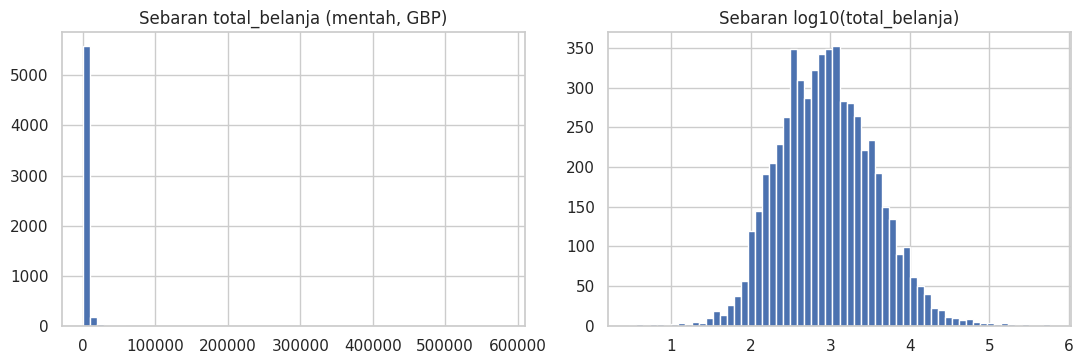

In [18]:
target = 'total_belanja'
print(pel[target].describe())
print('\nkemencengan (skewness) mentah:', round(pel[target].skew(), 2), '| setelah log1p:', round(np.log1p(pel[target]).skew(), 2))
print('nilai <= 0                   :', (pel[target] <= 0).sum(), '(target kotor dari pembelian, jadi harus positif)')
print('nilai unik                   :', pel[target].nunique(), 'dari', len(pel), '-> kontinu')
print('\n10 pelanggan teratas menyumbang', f'{pel[target].nlargest(10).sum() / pel[target].sum() * 100:.1f}% dari seluruh total belanja')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(pel[target], bins=60); ax[0].set_title('Sebaran total_belanja (mentah, GBP)')
ax[1].hist(np.log10(pel[target]), bins=60); ax[1].set_title('Sebaran log10(total_belanja)')
plt.tight_layout(); plt.show()

**Tafsir.** `total_belanja` sangat menceng ke kanan (skewness 25,3; median 856 GBP, rata-rata 2.917 GBP, maksimum 580.987 GBP), dan 10 pelanggan teratas menyumbang 16,1% seluruh nilai. Setelah transformasi log sebarannya hampir simetris (skewness log1p 0,27), jadi log layak dipertimbangkan agar residu regresi tidak melebar pada ekor.

Korelasi Pearson (mentah) dan Spearman dengan total_belanja:


,pearson,spearman
total_item,0.87,0.95
frekuensi,0.62,0.86
produk_unik,0.40,0.77
n_faktur_batal,0.41,0.58
tenure_hari,0.13,0.42
recency,-0.12,-0.51


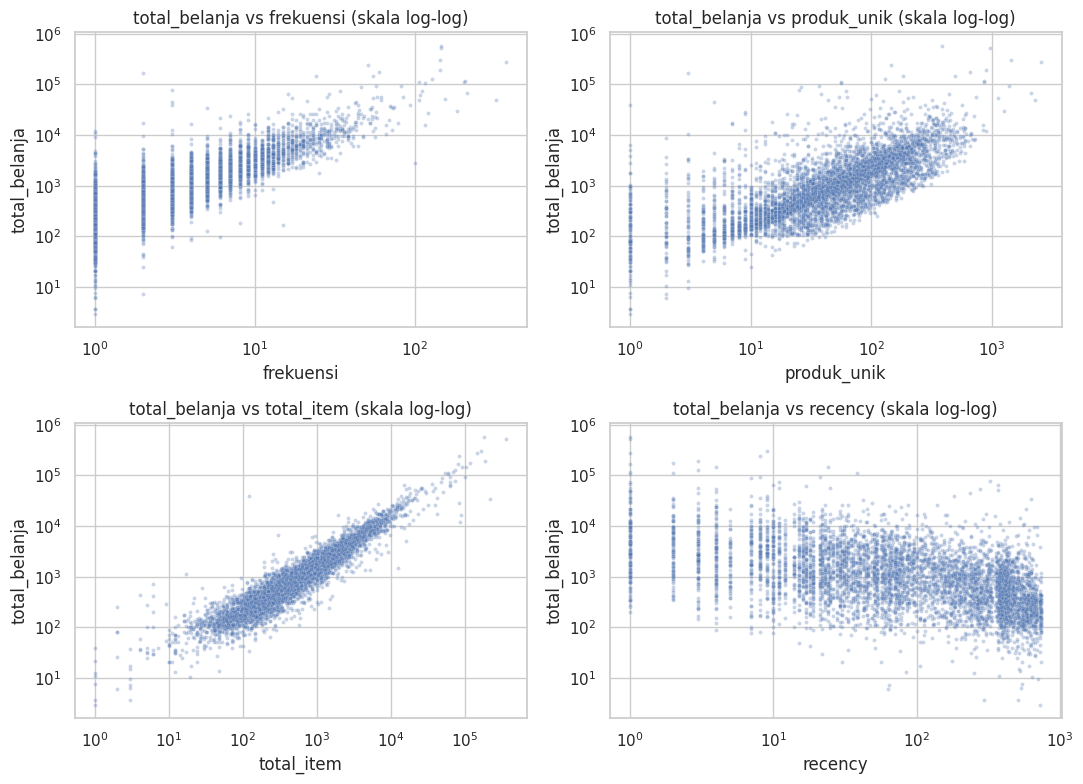

In [19]:
fitur_kandidat = ['recency', 'frekuensi', 'tenure_hari', 'produk_unik', 'total_item', 'n_faktur_batal']
print('Korelasi Pearson (mentah) dan Spearman dengan total_belanja:')
display(pd.DataFrame({'pearson': pel[fitur_kandidat].corrwith(pel[target]),
                      'spearman': pel[fitur_kandidat].corrwith(pel[target], method='spearman')}).sort_values('spearman', ascending=False))

fig, ax = plt.subplots(2, 2, figsize=(11, 8))
for a, f in zip(ax.ravel(), ['frekuensi', 'produk_unik', 'total_item', 'recency']):
    sns.scatterplot(x=pel[f].clip(lower=1), y=pel[target], s=8, alpha=0.3, ax=a)
    a.set_xscale('log'); a.set_yscale('log'); a.set_title(f'{target} vs {f} (skala log-log)')
plt.tight_layout(); plt.show()

**Tafsir.** Pada skala log-log `total_belanja` naik bersama `frekuensi` dan `produk_unik`, dan paling kuat dengan `total_item` (Spearman 0,95; Pearson 0,87). Namun `total_item` bukan penyebab, melainkan komponen nilai belanja (nilai = jumlah x harga), jadi perlu diwaspadai di Langkah 5. `recency` berkorelasi negatif sedang (Spearman -0,51): pelanggan yang baru berbelanja cenderung bernilai lebih besar.

**Perkiraan Anda sebelum memodelkan (wajib, dibandingkan dengan hasil pada Tahap 2):**
> _Tulis di sini fitur mana yang Anda duga paling berpengaruh pada `total_belanja` dan mengapa, sebelum Tahap 2. (Petunjuk: pikirkan hubungan antara frekuensi, jumlah barang, dan nilai.)_

### Cabang B - Klasifikasi (target: `kelompok_negara`, UK vs non-UK)

In [20]:
tb = 'kelompok_negara'
print('Tingkat PELANGGAN (unit analisis):')
print(pel[tb].value_counts()); print((pel[tb].value_counts(normalize=True) * 100).round(2))
garis_dasar = pel[tb].value_counts(normalize=True).max()
print(f'\n>>> garis dasar kelas mayoritas (pelanggan): {garis_dasar:.2%}')
print(f'    sebagai pembanding, tingkat BARIS bersih  : {(d["Country"] == "United Kingdom").mean():.2%}  '
      f'| baris mentah: {(df["Country"] == "United Kingdom").mean():.2%}')

print('\nIsi kelas non-UK (jumlah pelanggan per negara, 10 teratas):')
print(pel.loc[pel[tb] == 'non-UK', 'negara'].value_counts().head(10))
print('jumlah negara non-UK:', pel.loc[pel[tb] == 'non-UK', 'negara'].nunique(),
      '| yang hanya punya 1-2 pelanggan:', (pel.loc[pel[tb] == 'non-UK', 'negara'].value_counts() <= 2).sum())

Tingkat PELANGGAN (unit analisis):
kelompok_negara
UK        5334
non-UK     518
Name: count, dtype: int64
kelompok_negara
UK       91.15
non-UK    8.85
Name: proportion, dtype: float64

>>> garis dasar kelas mayoritas (pelanggan): 91.15%
    sebagai pembanding, tingkat BARIS bersih  : 89.99%  | baris mentah: 91.94%

Isi kelas non-UK (jumlah pelanggan per negara, 10 teratas):
negara
Germany        106
France          93
Spain           35
Belgium         28
Portugal        23
Switzerland     22
Netherlands     22
Sweden          19
Italy           17
Australia       14
Name: count, dtype: int64
jumlah negara non-UK: 40 | yang hanya punya 1-2 pelanggan: 15


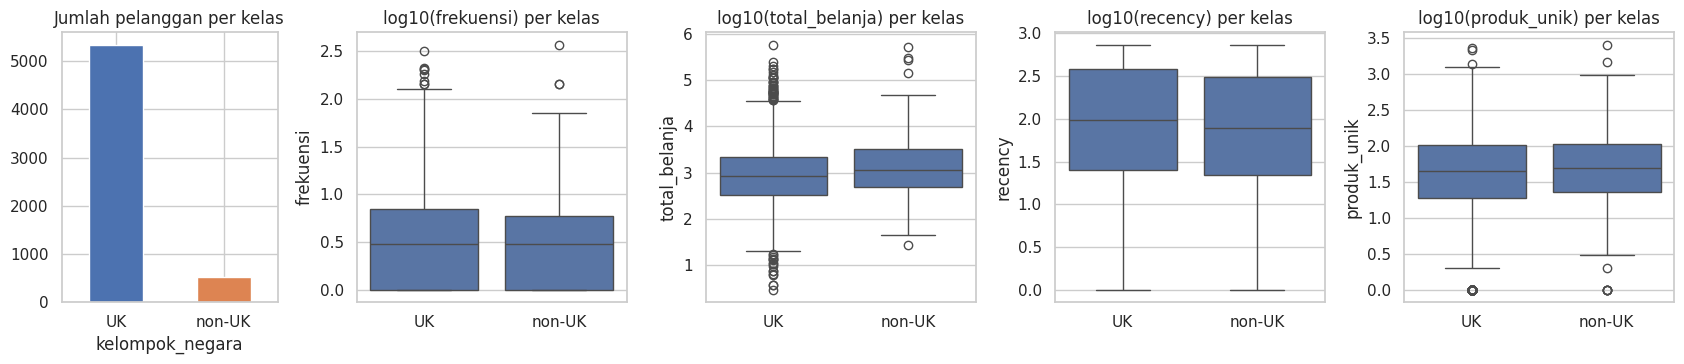

,frekuensi,total_belanja,recency,produk_unik,total_item
median per kelas,,,,,
UK,3.00,829.40,96.00,44.00,467.00
non-UK,3.00,"1,139.80",78.50,48.50,616.00


In [21]:
fig, ax = plt.subplots(1, 5, figsize=(17, 3.8), gridspec_kw={'width_ratios': [0.8, 1, 1, 1, 1]})
pel[tb].value_counts().plot.bar(ax=ax[0], color=['#4c72b0', '#dd8452'], rot=0); ax[0].set_title('Jumlah pelanggan per kelas')
for a, f in zip(ax[1:], ['frekuensi', 'total_belanja', 'recency', 'produk_unik']):
    sns.boxplot(x=pel[tb], y=np.log10(pel[f].clip(lower=1)), ax=a); a.set_title(f'log10({f}) per kelas'); a.set_xlabel('')
plt.tight_layout(); plt.show()
display(pel.groupby(tb)[['frekuensi', 'total_belanja', 'recency', 'produk_unik', 'total_item']].median().round(1).rename_axis('median per kelas'))

**Tafsir.** Kelasnya timpang: UK 91,15% dan non-UK 8,85% (518 pelanggan), sehingga garis dasarnya 91,15%. Kotak UK dan non-UK pada `frekuensi`, `total_belanja`, `recency`, dan `produk_unik` saling tumpang-tindih besar (median `frekuensi` sama-sama 3), jadi tidak ada fitur yang memisahkan kelas dengan jelas; hasil klasifikasi kemungkinan lemah dan itu temuan yang sah. Kelas non-UK juga terdiri atas 40 negara, 15 di antaranya hanya 1-2 pelanggan.

**Catatan untuk Tahap 2.**
- **Penskalaan wajib untuk k-NN** (mengukur jarak; `total_belanja` berskala ribuan, `frekuensi` satuan). Naive Bayes tidak memerlukannya. Sebutkan perbedaan ini saat membandingkan keduanya.
- **Naive Bayes** mengasumsikan fitur saling bebas; pasangan fitur berkorelasi kuat ditunjukkan di Langkah 5 (asumsi dilanggar).
- Kolom `negara` dan `n_negara` **tidak boleh jadi fitur** karena menyusun target (kebocoran definisional).
- Garis dasar di atas (kelas mayoritas) adalah pembanding minimum; evaluasi dengan recall, precision, F1, dan matriks konfusi, bukan akurasi saja.

### Cabang C - Klastering (K-Means, dasar: RFM)

,Recency,Frequency,Monetary
count,"5,852.00","5,852.00","5,852.00"
mean,199.73,6.25,"2,916.71"
std,208.52,12.75,"14,306.87"
min,0.00,1.00,2.95
25%,25.00,1.00,339.57
50%,95.00,3.00,856.02
75%,379.00,7.00,"2,241.03"
max,738.00,373.00,"580,987.04"


kemencengan mentah : {'Recency': 0.89, 'Frequency': 12.04, 'Monetary': 25.33}
kemencengan log1p  : {'Recency': -0.55, 'Frequency': 1.0, 'Monetary': 0.27}


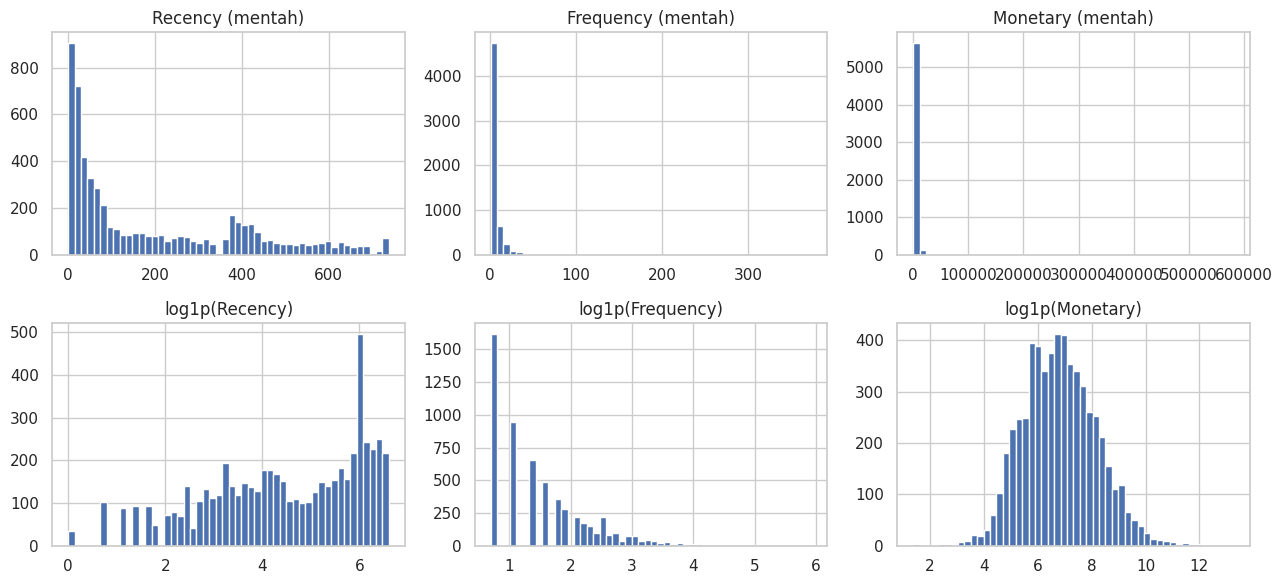

In [22]:
rfm = pel[['recency', 'frekuensi', 'total_belanja']].copy()
rfm.columns = ['Recency', 'Frequency', 'Monetary']
display(rfm.describe())
print('kemencengan mentah :', rfm.skew().round(2).to_dict())
print('kemencengan log1p  :', np.log1p(rfm).skew().round(2).to_dict())

fig, ax = plt.subplots(2, 3, figsize=(13, 6))
for i, k in enumerate(rfm.columns):
    ax[0, i].hist(rfm[k], bins=50); ax[0, i].set_title(f'{k} (mentah)')
    ax[1, i].hist(np.log1p(rfm[k]), bins=50); ax[1, i].set_title(f'log1p({k})')
plt.tight_layout(); plt.show()

**Tafsir.** Ketiga fitur RFM menceng: `Frequency` (skewness 12,0) dan `Monetary` (25,3) sangat kuat, `Recency` lebih ringan (0,89). Setelah log1p kemencengannya turun menjadi 1,0 dan 0,27, sedangkan `Recency` justru sedikit menceng ke kiri (-0,55), sehingga log lebih jelas berguna untuk F dan M; perlakuan R diputuskan di Tahap 2.

In [23]:
# Pencilan per fitur (dilaporkan, TIDAK dibuang otomatis)
for k in rfm.columns:
    q1, q3 = rfm[k].quantile([0.25, 0.75]); iqr = q3 - q1
    luar = ((rfm[k] < q1 - 1.5 * iqr) | (rfm[k] > q3 + 1.5 * iqr)).sum()
    print(f'{k:9s}: {luar:4d} pelanggan di luar pagar 1,5xIQR ({luar/len(rfm)*100:.1f}%)')
print('\n5 pelanggan Monetary tertinggi:')
display(pel.nlargest(5, 'total_belanja')[['total_belanja', 'frekuensi', 'recency', 'negara']])

# Efek penskalaan: simpangan baku sebelum vs sesudah
rfm_skala = pd.DataFrame(StandardScaler().fit_transform(np.log1p(rfm)), columns=rfm.columns, index=rfm.index)
print('\nsimpangan baku sebelum penskalaan:', rfm.std().round(1).to_dict())
print('simpangan baku sesudah log1p + StandardScaler:', rfm_skala.std().round(2).to_dict())
print('\nkorelasi antar fitur RFM (log1p):')
display(np.log1p(rfm).corr().round(2))

Recency  :    0 pelanggan di luar pagar 1,5xIQR (0.0%)
Frequency:  424 pelanggan di luar pagar 1,5xIQR (7.2%)
Monetary :  619 pelanggan di luar pagar 1,5xIQR (10.6%)

5 pelanggan Monetary tertinggi:


,total_belanja,frekuensi,recency,negara
Customer ID,,,,
18102,"580,987.04",145,0,United Kingdom
14646,"526,751.52",145,1,Netherlands
14156,"303,069.88",144,9,EIRE
14911,"272,252.79",373,1,EIRE
17450,"244,784.25",51,8,United Kingdom



simpangan baku sebelum penskalaan: {'Recency': 208.5, 'Frequency': 12.7, 'Monetary': 14306.9}
simpangan baku sesudah log1p + StandardScaler: {'Recency': 1.0, 'Frequency': 1.0, 'Monetary': 1.0}

korelasi antar fitur RFM (log1p):


,Recency,Frequency,Monetary
Recency,1.00,-0.56,-0.50
Frequency,-0.56,1.00,0.85
Monetary,-0.50,0.85,1.00


**Tafsir.** Pencilan: 424 pelanggan (7,2%) pada `Frequency` dan 619 (10,6%) pada `Monetary`; pelanggan 18102 (580.987 GBP) dan 14646 (526.752 GBP) jauh di atas yang lain, tetapi mereka pelanggan nyata dan bisa jadi klaster tersendiri, jadi tidak dibuang otomatis. Tanpa penskalaan, `Monetary` (simpangan baku 14.307) akan menenggelamkan `Recency` (208) dan `Frequency` (12,7); setelah log1p dan `StandardScaler` ketiganya berskala sama. `Frequency` dan `Monetary` berkorelasi 0,85 (log), jadi keduanya membawa informasi yang hampir sama; catat sebagai keterbatasan.

**Catatan untuk Tahap 2 (klastering).**
- Fitur dipilih dengan alasan: R, F, M adalah dasar segmentasi yang ditetapkan paket; ketiganya merangkum *kebaruan, keseringan, dan nilai* belanja.
- **Penskalaan wajib**; sebaran sangat menceng, jadi gunakan transformasi log sebelum `StandardScaler` (lihat di atas). Pencilan jangan dibuang otomatis; putuskan per fitur dengan alasan.
- **Jumlah klaster belum ditetapkan** pada Tahap 1; penentuannya (elbow, silhouette) adalah pekerjaan Tahap 2.
- **Bahan penafsiran klaster:** setelah klaster terbentuk, hitung per klaster: ukuran klaster, median R, F, M, rata-rata `produk_unik` dan `n_faktur_batal`, serta persen pelanggan non-UK. Dengan itu klaster bisa diberi nama bermakna (mis. "pelanggan setia bernilai tinggi", "pelanggan tidur").

## Langkah 5 - Hubungan antar variabel dan kebocoran data

In [24]:
target = 'total_belanja'
num_cols = ['recency', 'frekuensi', 'tenure_hari', 'produk_unik', 'total_item', 'rata_nilai_faktur',
            'n_faktur_batal', 'nilai_batal', 'total_belanja', 'total_belanja_bersih']
kor_t = pel[num_cols].corr()[target].drop(target).abs().sort_values(ascending=False)
display(kor_t.to_frame('|korelasi| dgn total_belanja'))
print('CURIGAI (>0.95):', list(kor_t[kor_t > 0.95].index))
print('Waspada (>0.80):', list(kor_t[(kor_t > 0.80) & (kor_t <= 0.95)].index))

# Pemeriksaan identitas (kebocoran definisional)
selisih1 = (pel['total_belanja'] - pel['frekuensi'] * pel['rata_nilai_faktur']).abs().max()
selisih2 = (pel['total_belanja_bersih'] - (pel['total_belanja'] + pel['nilai_batal'])).abs().max()
print(f'\nselisih maks |total_belanja - frekuensi x rata_nilai_faktur| = {selisih1:.6f}  (0 -> definisional)')
print(f'selisih maks |total_belanja_bersih - (total_belanja + nilai_batal)| = {selisih2:.6f}  (0 -> definisional)')
lg = np.log(pel[['total_belanja', 'frekuensi', 'rata_nilai_faktur']])
print('korelasi log(total_belanja) dengan log(rata_nilai_faktur):', round(lg.corr().loc['total_belanja', 'rata_nilai_faktur'], 3),
      '| dengan log(frekuensi):', round(lg.corr().loc['total_belanja', 'frekuensi'], 3))

,|korelasi| dgn total_belanja
total_belanja_bersih,0.98
total_item,0.87
frekuensi,0.62
n_faktur_batal,0.41
produk_unik,0.40
nilai_batal,0.28
rata_nilai_faktur,0.28
tenure_hari,0.13
recency,0.12


CURIGAI (>0.95): ['total_belanja_bersih']
Waspada (>0.80): ['total_item']

selisih maks |total_belanja - frekuensi x rata_nilai_faktur| = 0.000000  (0 -> definisional)
selisih maks |total_belanja_bersih - (total_belanja + nilai_batal)| = 0.000000  (0 -> definisional)
korelasi log(total_belanja) dengan log(rata_nilai_faktur): 0.689 | dengan log(frekuensi): 0.854


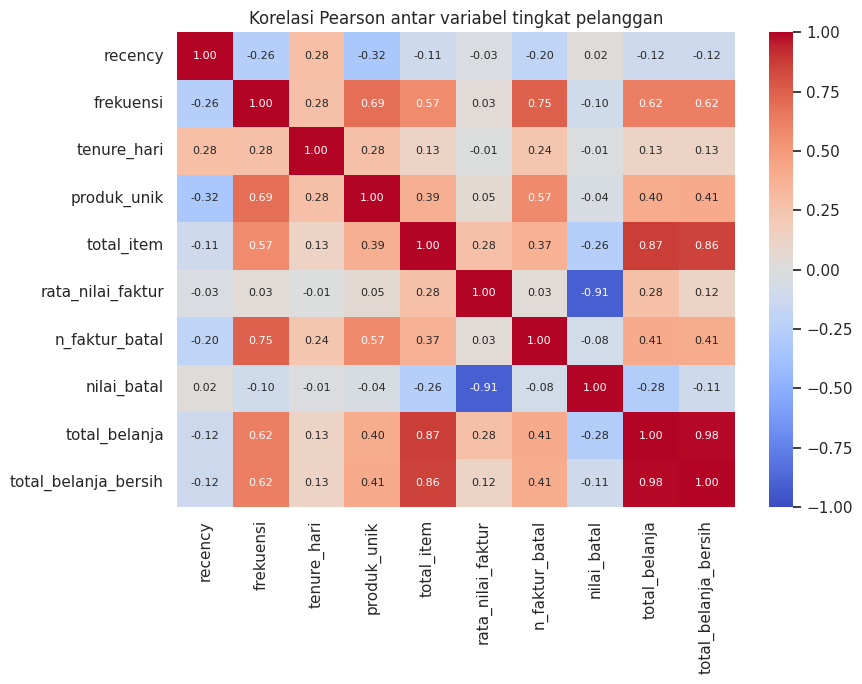

,variabel_1,variabel_2,korelasi
0,total_belanja,total_belanja_bersih,0.98
1,rata_nilai_faktur,nilai_batal,-0.91
2,total_item,total_belanja,0.87
3,total_item,total_belanja_bersih,0.86


In [25]:
korm = pel[num_cols].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(korm, annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1, annot_kws={'size': 8})
plt.title('Korelasi Pearson antar variabel tingkat pelanggan'); plt.tight_layout(); plt.show()

# Multikolinearitas: pasangan |r| > 0.8
atas = korm.where(np.triu(np.ones(korm.shape), 1).astype(bool)).stack().reset_index()
atas.columns = ['variabel_1', 'variabel_2', 'korelasi']
display(atas[atas['korelasi'].abs() > 0.8].sort_values('korelasi', key=abs, ascending=False).reset_index(drop=True))

**Tafsir.** Hanya `total_belanja_bersih` (0,98) yang melewati ambang kebocoran 0,95, dan `total_item` (0,87) berada di zona waspada. Pasangan berkorelasi di atas 0,8: `total_belanja`-`total_belanja_bersih` (0,98), `rata_nilai_faktur`-`nilai_batal` (-0,91), `total_item`-`total_belanja` (0,87), dan `total_item`-`total_belanja_bersih` (0,86). Pelajaran penting: `rata_nilai_faktur` hanya berkorelasi 0,28 dengan target, tetapi uji identitas menunjukkan selisih 0 (`total_belanja` = `frekuensi` x `rata_nilai_faktur` persis). Korelasi rendah tidak menjamin bebas kebocoran, jadi uji definisional wajib dilakukan terpisah.

### Rancangan dua skenario untuk Tahap 2

In [26]:
bocor = pd.DataFrame([
    ['rata_nilai_faktur', 'Definisional', 'total_belanja = frekuensi x rata_nilai_faktur (selisih 0)', 'Dikeluarkan pada Skenario A, dimasukkan pada Skenario B'],
    ['total_belanja_bersih', 'Definisional / pengganti langsung', 'Memuat total_belanja ditambah nilai_batal', 'Dikeluarkan pada Skenario A'],
    ['nilai_batal', 'Pengganti sebagian', 'Komponen penyusun total_belanja_bersih', 'Dikeluarkan (hanya n_faktur_batal yang dipakai)'],
    ['total_item', 'Hampir definisional (waspada)', 'Jumlah barang; nilai = jumlah x harga, korelasi tinggi (lihat tabel)', 'Dipertahankan tetapi dilaporkan, uji dengan/tanpa'],
    ['negara, n_negara', 'Definisional (hanya untuk Cabang B)', 'Menyusun target kelompok_negara', 'Dikeluarkan dari fitur klasifikasi'],
    ['Seluruh fitur', 'Waktu', 'Fitur dan target dihitung dari jendela waktu yang sama', 'Lihat uji jendela waktu di bawah'],
], columns=['Fitur', 'Bentuk kebocoran', 'Bukti', 'Rencana'])
display(bocor)

,Fitur,Bentuk kebocoran,Bukti,Rencana
0,rata_nilai_faktur,Definisional,total_belanja = frekuensi x rata_nilai_faktur ...,"Dikeluarkan pada Skenario A, dimasukkan pada S..."
1,total_belanja_bersih,Definisional / pengganti langsung,Memuat total_belanja ditambah nilai_batal,Dikeluarkan pada Skenario A
2,nilai_batal,Pengganti sebagian,Komponen penyusun total_belanja_bersih,Dikeluarkan (hanya n_faktur_batal yang dipakai)
3,total_item,Hampir definisional (waspada),"Jumlah barang; nilai = jumlah x harga, korelas...","Dipertahankan tetapi dilaporkan, uji dengan/tanpa"
4,"negara, n_negara",Definisional (hanya untuk Cabang B),Menyusun target kelompok_negara,Dikeluarkan dari fitur klasifikasi
5,Seluruh fitur,Waktu,Fitur dan target dihitung dari jendela waktu y...,Lihat uji jendela waktu di bawah


In [27]:
# Rancangan alternatif tanpa kebocoran waktu: fitur dari jendela awal, target dari jendela berikutnya
BATAS, AKHIR = pd.Timestamp('2010-12-01'), pd.Timestamp('2011-12-01')
awal = beli[beli['InvoiceDate'] < BATAS]
lanjut = beli[(beli['InvoiceDate'] >= BATAS) & (beli['InvoiceDate'] < AKHIR)]
pel_awal = awal['Customer ID'].unique()
belanja_lanjut = lanjut.groupby('Customer ID')['nilai'].sum()
ada = np.isin(pel_awal, belanja_lanjut.index)
print(f'pelanggan aktif pada jendela fitur (< {BATAS.date()}): {len(pel_awal):,}')
print(f'  yang berbelanja lagi pada jendela target ({BATAS.date()} s.d. {AKHIR.date()}): {ada.sum():,} ({ada.mean()*100:.1f}%)')
print(f'  yang tidak berbelanja lagi (target = 0 -> perlu keputusan): {(~ada).sum():,}')

pelanggan aktif pada jendela fitur (< 2010-12-01): 4,239
  yang berbelanja lagi pada jendela target (2010-12-01 s.d. 2011-12-01): 2,708 (63.9%)
  yang tidak berbelanja lagi (target = 0 -> perlu keputusan): 1,531


**Tafsir.** Pada rancangan jendela waktu, 4.239 pelanggan aktif sebelum 1 Desember 2010 dan hanya 2.708 (63,9%) berbelanja lagi setahun berikutnya; 1.531 pelanggan akan bertarget nol. Rancangan ini menghapus kebocoran waktu tetapi mengubah pertanyaan penelitian, sehingga perlu diputuskan dan diberi alasan di Tahap 2.

**Aturan dosen:** jika R-kuadrat Tahap 2 > 0,95 atau akurasi > 0,98, **anggap itu kesalahan** sampai dibuktikan sebaliknya. Pada paket ini kebocoran paling mungkin terjadi bila `rata_nilai_faktur` (atau `total_belanja_bersih`) ikut dimasukkan sebagai fitur regresi `total_belanja`.

## Langkah 6 - Visualisasi yang menjawab pertanyaan (rekap)

| # | Pertanyaan | Grafik | Letak | Temuan utama |
|---|---|---|---|---|
| 1 | Kapan Customer ID kosong? | Garis per bulan | 3a | lihat tafsir 3a |
| 2 | Seberapa ekstrem Quantity/Price? | Histogram log | 3e | lihat tafsir 3e |
| 3 | Bagaimana sebaran total belanja? | Histogram mentah vs log | 4A | menceng kuat; log mendekati simetris |
| 4 | Fitur mana berhubungan dengan total belanja? | Sebar log-log | 4A | hubungan positif pada frekuensi dan produk_unik |
| 5 | Seberapa timpang kelas UK/non-UK dan apakah fitur memisahkan? | Batang + kotak | 4B | kelas timpang; pemisahan lemah |
| 6 | Bagaimana sebaran RFM? | Histogram mentah vs log | 4C | menceng; perlu log + skala |
| 7 | Fitur mana saling berkorelasi kuat dan mana yang membocorkan? | Peta panas | 5 | lihat tabel pasangan > 0,8 |

Tujuh grafik, masing-masing dengan tafsir di bawahnya; sisanya berupa tabel.

## Langkah 7 - Catat keputusan dan simpan data bersih

In [28]:
# Uji sensitivitas: seberapa besar keputusan pembersihan mengubah total belanja pelanggan?
def monet(dx):
    b = dx[(~dx['batal']) & (dx['Quantity'] > 0)]
    return b.groupby('Customer ID')['nilai'].sum()

m_utama = monet(d)
baris = []
for nama, kw in [('tanpa buang duplikat', dict(dedupe=False)),
                 ('tanpa buang kode non-produk', dict(buang_nonproduk=False))]:
    dx, _ = bersihkan(df, **kw)
    m_var = monet(dx)                      # pelanggan yang punya pembelian pada varian ini
    mx = m_var.reindex(m_utama.index)      # dibandingkan pada pelanggan yang sama dengan keputusan utama
    baris.append({'varian': nama, 'jumlah_pelanggan': len(m_var),
                  'total_belanja_seluruhnya': mx.sum(),
                  'selisih_total_persen': (mx.sum() / m_utama.sum() - 1) * 100,
                  'pelanggan_berubah_>5%': int(((mx / m_utama - 1).abs() > 0.05).sum()),
                  'korelasi_Spearman': mx.corr(m_utama, method='spearman')})
baris.insert(0, {'varian': 'KEPUTUSAN UTAMA', 'jumlah_pelanggan': len(m_utama), 'total_belanja_seluruhnya': m_utama.sum(),
                 'selisih_total_persen': 0.0, 'pelanggan_berubah_>5%': 0, 'korelasi_Spearman': 1.0})
display(pd.DataFrame(baris))

pel['total_belanja_dgn_batal_pct'] = (pel['nilai_batal'].abs() / pel['total_belanja'] * 100)
print('\nEfek memasukkan pembatalan (Monetary bersih vs kotor):')
print('  pelanggan dengan total_belanja_bersih <= 0 :', (pel['total_belanja_bersih'] <= 0).sum())
print('  pengurangan total belanja seluruh pelanggan :', f"{(1 - pel['total_belanja_bersih'].sum() / pel['total_belanja'].sum()) * 100:.2f}%")
pel = pel.drop(columns='total_belanja_dgn_batal_pct')

,varian,jumlah_pelanggan,total_belanja_seluruhnya,selisih_total_persen,pelanggan_berubah_>5%,korelasi_Spearman
0,KEPUTUSAN UTAMA,5852,"17,068,582.72",0.00,0,1.00
1,tanpa buang duplikat,5852,"17,434,464.73",2.14,579,1.00
2,tanpa buang kode non-produk,5878,"17,331,255.98",1.54,417,1.00



Efek memasukkan pembatalan (Monetary bersih vs kotor):
  pelanggan dengan total_belanja_bersih <= 0 : 19
  pengurangan total belanja seluruh pelanggan : 4.15%


**Tafsir sensitivitas.** Membuang duplikat menurunkan total belanja seluruh pelanggan 2,14% (17,43 juta menjadi 17,07 juta GBP) dan mengubah nilai 579 pelanggan lebih dari 5%; membuang kode non-produk mengubahnya 1,54% (417 pelanggan lebih dari 5%). Peringkat pelanggan hampir tidak berubah (Spearman sekitar 1,00), tetapi nilai Monetary berubah, sehingga keputusan tetap harus diberi alasan. Soal pembatalan: memasukkannya mengurangi total 4,15% dan 19 pelanggan menjadi bernilai nol atau negatif. Contoh paling ekstrem pelanggan 12346: `total_belanja` kotor 77.353 GBP tetapi bersih hanya 169 GBP (membeli 74.215 unit lalu membatalkannya). Notebook ini memakai nilai kotor sebagai target utama dan menyimpan versi bersihnya; **pilihan ini harus Anda putuskan dan alasankan sendiri.**

In [29]:
tabel_keputusan = pd.DataFrame(log)
tabel_keputusan['Baris terpengaruh'] = tabel_keputusan['Baris terpengaruh'].map('{:,}'.format)
tambahan = pd.DataFrame([
    ['Satu baris vs satu pelanggan', 'Baris = item faktur; target dan RFM per pelanggan', f'Diagregasi ke {len(pel):,} pelanggan', 'Unit analisis harus sesuai target', f'{len(d):,} baris -> {len(pel):,} pelanggan'],
    ['rata_nilai_faktur, total_belanja_bersih, nilai_batal', 'Kebocoran definisional terhadap total_belanja (selisih 0)', 'Dikeluarkan dari fitur regresi (Skenario A)', 'Menyusun target', '0 baris, 3 kolom'],
    ['negara, n_negara', 'Menyusun target klasifikasi', 'Dikeluarkan dari fitur klasifikasi', 'Kebocoran definisional', '0 baris, 2 kolom'],
    ['total_belanja', 'Sangat menceng kanan', 'Dipertahankan mentah di berkas; transformasi log dilakukan di Tahap 2', 'Transformasi bagian pemodelan, bukan pembersihan', '0'],
], columns=tabel_keputusan.columns)
tabel_keputusan = pd.concat([tabel_keputusan, tambahan], ignore_index=True)
pd.set_option('display.max_colwidth', 80)
display(tabel_keputusan)

,Kolom / baris,Temuan,Keputusan,Alasan,Baris terpengaruh
0,Baris identik penuh,Salinan ganda pada faktur dan menit yang sama,Dibuang (sisakan satu),Pola pencatatan ganda; dampaknya diuji pada uji sensitivitas Langkah 7,"34,335"
1,Customer ID kosong,Pembeli tanpa akun; tidak dapat dihubungkan ke pelanggan,Baris dibuang,Unit analisis adalah pelanggan; baris tanpa ID tidak bisa diagregasi,"235,151"
2,StockCode non-produk,"POST, DOT, M, C2, D, BANK CHARGES, ADJUST, CRUK, TEST, dll.",Baris dibuang,"Ongkir, biaya, dan penyesuaian bukan belanja produk; menggembungkan Monetary","3,660"
3,Price <= 0,Harga nol/negatif (penyesuaian dan koreksi stok),Baris dibuang,Harga satuan tidak mungkin nol/negatif pada penjualan nyata,60
4,Description,Spasi berlebih dan huruf besar/kecil tidak seragam,"Diseragamkan (strip, UPPER)",Satu produk tidak boleh terhitung sebagai beberapa label,0
5,Invoice berawalan C,Nota kredit/pembatalan (Quantity negatif),"Dipertahankan, ditandai kolom batal",Dipakai sebagai fitur pembatalan; Monetary dihitung dua versi (kotor dan ber...,0
6,Satu baris vs satu pelanggan,Baris = item faktur; target dan RFM per pelanggan,"Diagregasi ke 5,852 pelanggan",Unit analisis harus sesuai target,"794,165 baris -> 5,852 pelanggan"
7,"rata_nilai_faktur, total_belanja_bersih, nilai_batal",Kebocoran definisional terhadap total_belanja (selisih 0),Dikeluarkan dari fitur regresi (Skenario A),Menyusun target,"0 baris, 3 kolom"
8,"negara, n_negara",Menyusun target klasifikasi,Dikeluarkan dari fitur klasifikasi,Kebocoran definisional,"0 baris, 2 kolom"
9,total_belanja,Sangat menceng kanan,Dipertahankan mentah di berkas; transformasi log dilakukan di Tahap 2,"Transformasi bagian pemodelan, bukan pembersihan",0


In [30]:
# Kamus data (format Lampiran A)
K = []
def k(tbl, nama, arti, satuan, tipe, peran, catatan): K.append([tbl, nama, arti, satuan, tipe, peran, catatan])
# Tabel transaksi bersih
k('transaksi', 'Invoice', 'Nomor faktur (awalan C = pembatalan)', '-', 'teks (identifier)', 'identifier', 'dipecah menjadi penanda batal')
k('transaksi', 'StockCode', 'Kode produk', '-', 'teks (identifier)', 'identifier', 'kode non-produk sudah dibuang')
k('transaksi', 'Description', 'Nama produk', '-', 'teks', 'dibuang', 'diseragamkan (strip, UPPER)')
k('transaksi', 'Quantity', 'Jumlah unit pada baris faktur', 'unit', 'numerik bulat', 'fitur (diagregasi)', 'negatif hanya pada nota batal')
k('transaksi', 'InvoiceDate', 'Waktu faktur', '-', 'tanggal-waktu', 'dasar Recency', 'rentang 2009-12-01 s.d. 2011-12-09')
k('transaksi', 'Price', 'Harga satuan', 'GBP', 'numerik desimal', 'fitur (diagregasi)', 'baris Price <= 0 sudah dibuang')
k('transaksi', 'Customer ID', 'Nomor pelanggan', '-', 'teks (identifier)', 'identifier', 'baris kosong sudah dibuang')
k('transaksi', 'Country', 'Negara pelanggan', '-', 'kategori', 'target B (diagregasi)', '43 nilai awal; Unspecified/European Community perlu perhatian')
k('transaksi', 'batal', 'Penanda nota batal', '-', 'boolean', 'fitur (diagregasi)', 'turunan dari awalan C')
k('transaksi', 'nilai', 'Quantity x Price', 'GBP', 'numerik desimal', 'dasar Monetary', 'turunan')
# Tabel pelanggan
k('pelanggan', 'Customer ID', 'Nomor pelanggan', '-', 'teks (identifier)', 'identifier', 'kunci unik')
k('pelanggan', 'total_belanja', 'Total nilai pembelian kotor (tanpa pembatalan)', 'GBP', 'numerik desimal', 'target A / fitur M pada klastering', 'menceng kuat; pakai log di Tahap 2')
k('pelanggan', 'frekuensi', 'Jumlah faktur pembelian berbeda', 'faktur', 'numerik bulat', 'fitur / F pada klastering', 'menceng')
k('pelanggan', 'recency', 'Hari sejak pembelian terakhir terhadap tanggal acuan', 'hari', 'numerik bulat', 'fitur / R pada klastering', 'makin kecil makin baru')
k('pelanggan', 'tenure_hari', 'Hari sejak pembelian pertama', 'hari', 'numerik bulat', 'fitur', 'berkorelasi dengan recency dan frekuensi')
k('pelanggan', 'produk_unik', 'Jumlah kode produk berbeda yang pernah dibeli', 'produk', 'numerik bulat', 'fitur', '-')
k('pelanggan', 'total_item', 'Jumlah unit seluruh pembelian', 'unit', 'numerik bulat', 'fitur (waspada)', 'korelasi tinggi dengan target A')
k('pelanggan', 'n_faktur_batal', 'Jumlah faktur nota batal', 'faktur', 'numerik bulat', 'fitur', 'banyak bernilai nol')
k('pelanggan', 'rata_nilai_faktur', 'total_belanja / frekuensi', 'GBP', 'numerik desimal', 'dibuang (Skenario A)', 'bocor definisional ke target A')
k('pelanggan', 'nilai_batal', 'Total nilai nota batal (negatif)', 'GBP', 'numerik desimal', 'dibuang', 'bocor sebagian ke total_belanja_bersih')
k('pelanggan', 'total_belanja_bersih', 'total_belanja + nilai_batal', 'GBP', 'numerik desimal', 'dibuang', 'memuat target A')
k('pelanggan', 'negara', 'Negara modus pelanggan', '-', 'kategori', 'dibuang dari fitur', 'menyusun target B')
k('pelanggan', 'n_negara', 'Jumlah negara berbeda pada transaksi pelanggan', '-', 'numerik bulat', 'dibuang dari fitur', 'hampir selalu 1')
k('pelanggan', 'kelompok_negara', 'UK vs non-UK', '-', 'kategori biner', 'target B', 'kelas timpang')
k('pelanggan', 'terakhir / pertama', 'Tanggal pembelian terakhir / pertama', '-', 'tanggal-waktu', 'dibuang', 'hanya dasar penghitungan')
kamus = pd.DataFrame(K, columns=['Tabel', 'Nama kolom', 'Arti dalam bahasa Indonesia', 'Satuan', 'Tipe yang ditetapkan', 'Peran', 'Catatan mutu'])
display(kamus)

,Tabel,Nama kolom,Arti dalam bahasa Indonesia,Satuan,Tipe yang ditetapkan,Peran,Catatan mutu
0,transaksi,Invoice,Nomor faktur (awalan C = pembatalan),-,teks (identifier),identifier,dipecah menjadi penanda batal
1,transaksi,StockCode,Kode produk,-,teks (identifier),identifier,kode non-produk sudah dibuang
2,transaksi,Description,Nama produk,-,teks,dibuang,"diseragamkan (strip, UPPER)"
3,transaksi,Quantity,Jumlah unit pada baris faktur,unit,numerik bulat,fitur (diagregasi),negatif hanya pada nota batal
4,transaksi,InvoiceDate,Waktu faktur,-,tanggal-waktu,dasar Recency,rentang 2009-12-01 s.d. 2011-12-09
5,transaksi,Price,Harga satuan,GBP,numerik desimal,fitur (diagregasi),baris Price <= 0 sudah dibuang
6,transaksi,Customer ID,Nomor pelanggan,-,teks (identifier),identifier,baris kosong sudah dibuang
7,transaksi,Country,Negara pelanggan,-,kategori,target B (diagregasi),43 nilai awal; Unspecified/European Community perlu perhatian
8,transaksi,batal,Penanda nota batal,-,boolean,fitur (diagregasi),turunan dari awalan C
9,transaksi,nilai,Quantity x Price,GBP,numerik desimal,dasar Monetary,turunan


In [31]:
# Simpan keluaran Tahap 1
kolom_simpan = ['total_belanja', 'frekuensi', 'recency', 'tenure_hari', 'produk_unik', 'total_item',
                'n_faktur_batal', 'rata_nilai_faktur', 'nilai_batal', 'total_belanja_bersih',
                'negara', 'n_negara', 'kelompok_negara']
pel_out = pel[kolom_simpan].reset_index()
pel_out.to_csv('data_bersih_pelanggan.csv', index=False)
d.drop(columns=['nilai']).to_csv('data_bersih_transaksi.csv', index=False)
kamus.to_csv('kamus_data.csv', index=False)
tabel_keputusan.to_csv('tabel_keputusan.csv', index=False)

print('ukuran awal (mentah)      :', df.shape)
print('ukuran bersih transaksi   :', d.shape)
print('ukuran bersih pelanggan   :', pel_out.shape, '<- dataset utama untuk pemodelan Tahap 2')
print('berkas tersimpan          : data_bersih_pelanggan.csv, data_bersih_transaksi.csv, kamus_data.csv, tabel_keputusan.csv')

ukuran awal (mentah)      : (1067371, 8)
ukuran bersih transaksi   : (794165, 10)
ukuran bersih pelanggan   : (5852, 14) <- dataset utama untuk pemodelan Tahap 2
berkas tersimpan          : data_bersih_pelanggan.csv, data_bersih_transaksi.csv, kamus_data.csv, tabel_keputusan.csv
